In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import math

In [2]:
df_travellers_spending=pd.read_csv(r"C:\Users\PatrickNjuguna\Downloads\siat_consumer_spending_itineraries.csv")
print("---travellers_spending dataset Info--")
print("df_travellers_spending.info()")
print("\n--- Summary statistics--")
print(df_travellers_spending.describe())

---travellers_spending dataset Info--
df_travellers_spending.info()

--- Summary statistics--
       Respondent_ID  Total_Spend_USD  Travel_Party_Size
count   10500.000000     10500.000000       10500.000000
mean    15250.500000      1550.930130           1.929524
std      3031.233247       754.688853           1.174703
min     10001.000000       108.300000           1.000000
25%     12625.750000      1012.017500           1.000000
50%     15250.500000      1412.080000           1.000000
75%     17875.250000      1936.177500           3.000000
max     20500.000000      7734.440000           5.000000


### The above dat on consumer spending contains 10500 row and six columns(Respondend ID,Trpi_Purpose,Total_spend_USD, Primary_city_visited,Accommodation type,Travel_party_size)

In [3]:
df_travellers_spending.columns=(
    df_travellers_spending.columns.str.strip()
)
df_travellers_spending= df_travellers_spending.rename(columns= {
    "Respondent_ID":"Respondent",
    "Trip_Purpose": "Travel_Reason",
    "Total_Spend_USD":"Expenses",
    "Primary_City_Visited":"City",
    "Accommodation_Type": "Accommodation",
    "Travel_Party_Size":"Pax"})
print(df_travellers_spending.columns.tolist())

['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax']


In [4]:
print("Dataset shape:", df_travellers_spending.shape)
print("\nColumns name:")
print(df_travellers_spending.columns.tolist())
print("\nTravel Purpose categories:")
print(df_travellers_spending["Travel_Reason"].value_counts(dropna=False))

print("\nSpending Summary:")
print(df_travellers_spending["Expenses"].describe())
print("\nMissing values:")
print(df_travellers_spending.isnull().sum())

Dataset shape: (10500, 6)

Columns name:
['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax']

Travel Purpose categories:
Travel_Reason
Leisure/Vacation           5884
Visit Friends/Relatives    2234
Business                   1883
Education/Other             499
Name: count, dtype: int64

Spending Summary:
count    10500.000000
mean      1550.930130
std        754.688853
min        108.300000
25%       1012.017500
50%       1412.080000
75%       1936.177500
max       7734.440000
Name: Expenses, dtype: float64

Missing values:
Respondent       0
Travel_Reason    0
Expenses         0
City             0
Accommodation    0
Pax              0
dtype: int64


## Joining the consumer spending (SIAT Consumer spending & (BEA) US Bureau of Economic Analysis data containing state year,per capita personal income aand real GDP

In [5]:
import zipfile## the file comes as zip containing different years of data
zip_path= r"C:\Users\PatrickNjuguna\Downloads\SASUMMARY.zip"
with zipfile.ZipFile(zip_path,"r") as zip_ref:
    for file in zip_ref.namelist():
        print(file)

SASUMMARY_AK_1998_2025.csv
SASUMMARY_AZ_1998_2025.csv
SASUMMARY_AR_1998_2025.csv
SASUMMARY_CA_1998_2025.csv
SASUMMARY_CO_1998_2025.csv
SASUMMARY_CT_1998_2025.csv
SASUMMARY_DE_1998_2025.csv
SASUMMARY_DC_1998_2025.csv
SASUMMARY_FL_1998_2025.csv
SASUMMARY_GA_1998_2025.csv
SASUMMARY_HI_1998_2025.csv
SASUMMARY_ID_1998_2025.csv
SASUMMARY_IL_1998_2025.csv
SASUMMARY_IN_1998_2025.csv
SASUMMARY_IA_1998_2025.csv
SASUMMARY_KS_1998_2025.csv
SASUMMARY_KY_1998_2025.csv
SASUMMARY_LA_1998_2025.csv
SASUMMARY_ME_1998_2025.csv
SASUMMARY_MD_1998_2025.csv
SASUMMARY_MA_1998_2025.csv
SASUMMARY_MI_1998_2025.csv
SASUMMARY_MN_1998_2025.csv
SASUMMARY_MS_1998_2025.csv
SASUMMARY_MO_1998_2025.csv
SASUMMARY_MT_1998_2025.csv
SASUMMARY_NE_1998_2025.csv
SASUMMARY_NV_1998_2025.csv
SASUMMARY_NH_1998_2025.csv
SASUMMARY_NJ_1998_2025.csv
SASUMMARY_NM_1998_2025.csv
SASUMMARY_NY_1998_2025.csv
SASUMMARY_NC_1998_2025.csv
SASUMMARY_ND_1998_2025.csv
SASUMMARY_OH_1998_2025.csv
SASUMMARY_OK_1998_2025.csv
SASUMMARY_OR_1998_2025.csv
S

In [6]:
with zipfile.ZipFile(zip_path, "r") as y:
    # Inspect the dataset definition
    definition = y.read("SASUMMARY__definition.xml").decode(
        "utf-8", errors="replace"
    )
    print("DATASET DEFINITION:")
    print(definition[:6000])

    # Inspect one state's dataset
    with y.open("SASUMMARY_CA_1998_2025.csv") as f:
        df_state_sample = pd.read_csv(f)

print("\nCOLUMN NAMES:")
print(df_state_sample.columns.tolist())

print("\nDATASET SHAPE:")
print(df_state_sample.shape)

print("\nFIRST FIVE ROWS:")
display(df_state_sample.head())

print("\nDATA TYPES AND NON-NULL COUNTS:")
df_state_sample.info()

DATASET DEFINITION:
<TABLE_DEFINITIONS Table="SASUMMARY" Name="State annual summary statistics: personal income, GDP, consumer spending, price indexes, and employment" Source="USDOC/BEA/RD"><LINE><Code>1</Code><Description>Real GDP (millions of chained 2017 dollars)</Description><Definition>Real GDP by state is an inflation-adjusted measure of each state's gross product that is based on national prices for the goods and services produced within the state. The real estimates of gross domestic product (GDP) by state are measured in chained (2017) dollars.</Definition></LINE><LINE><Code>2</Code><Description>Real personal income (millions of constant (2017) dollars)</Description><Definition>Real personal income is personal income at RPPs divided by the national PCE price index. It is estimated for states.</Definition></LINE><LINE><Code>3</Code><Description>Real PCE (millions of constant (2017) dollars)</Description><Definition>Real personal consumption expenditures for states are personal 

,GeoFIPS,GeoName,Region,TableName,LineCode,IndustryClassification,Description,Unit,1998,1999,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,"""06000""",California,8.0,SASUMMARY,1.0,...,Real GDP (millions of chained 2017 dollars) 1/,Millions of chained 2017 dollars,1538612.3,1655438.5,...,2623711.7,2740550.3,2850608.8,2969065.6,2933001.7,3167935.6,3161153.4,3203898.4,3312182.2,3429343.2
1,"""06000""",California,8.0,SASUMMARY,2.0,...,Real personal income (millions of constant (2...,Millions of constant 2017 dollars,(NA),(NA),...,2031874.1,2072501.7,2116099.3,2211945.4,2371052.9,2480586.7,2314340.1,2355848.6,2485266.8,(NA)
2,"""06000""",California,8.0,SASUMMARY,3.0,...,Real PCE (millions of constant (2017) dollars...,Millions of constant 2017 dollars,(NA),(NA),...,1541503.9,1578516.1,1625719.9,1687457.4,1611943.7,1768334.7,1812361.5,1866148.5,1945732.3,(NA)
3,"""06000""",California,8.0,SASUMMARY,4.0,...,Gross domestic product (GDP),Millions of current dollars,1143672.5,1239773.5,...,2586485.2,2740550.3,2899530.9,3068625.8,3076253.6,3435095.5,3623524.5,3820394.5,4054078.0,4297449.8
4,"""06000""",California,8.0,SASUMMARY,5.0,...,Personal income,Millions of current dollars,953360.5,1022682.7,...,2191559.2,2295467.5,2411460.0,2540163.3,2770813.3,3020255.4,3021298.9,3186186.4,3415317.2,3579656.8



DATA TYPES AND NON-NULL COUNTS:
<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   GeoFIPS                 19 non-null     str    
 1   GeoName                 15 non-null     str    
 2   Region                  15 non-null     float64
 3   TableName               15 non-null     str    
 4   LineCode                15 non-null     float64
 5   IndustryClassification  15 non-null     str    
 6   Description             15 non-null     str    
 7   Unit                    15 non-null     str    
 8   1998                    15 non-null     str    
 9   1999                    15 non-null     str    
 10  2000                    15 non-null     str    
 11  2001                    15 non-null     str    
 12  2002                    15 non-null     str    
 13  2003                    15 non-null     str    
 14  2004                  

In [7]:
print(
    df_state_sample[
        ["LineCode", "Description", "Unit"]
    ].to_string(index=False)
)
    ## during analysis i noticed califonia had 19 row and 36 columns and we are only interested on per capita personal income
    ## this is linecode 10.o

 LineCode                                                    Description                              Unit
      1.0                 Real GDP (millions of chained 2017 dollars) 1/  Millions of chained 2017 dollars
      2.0  Real personal income (millions of constant (2017) dollars) 2/ Millions of constant 2017 dollars
      3.0              Real PCE (millions of constant (2017) dollars) 3/ Millions of constant 2017 dollars
      4.0                                  Gross domestic product (GDP)        Millions of current dollars
      5.0                                               Personal income        Millions of current dollars
      6.0                                    Disposable personal income        Millions of current dollars
      7.0                             Personal consumption expenditures        Millions of current dollars
      8.0                             Real per capita personal income 4/             Constant 2017 dollars
      9.0                            

In [8]:
selected_codes=[10,11,13]## they have economic indicators
califonia_indicators= df_state_sample[
    df_state_sample["LineCode"].isin(selected_codes)
].copy()

year_columns=[
    col for col in califonia_indicators.columns
    if str(col).isdigit()
]
display(
    ['geoName','LineCode','Description','Unit']+year_columns[-5:]


)
### We are going to work with the last 5 years 2021,2022,2023,2024,2025


['geoName',
 'LineCode',
 'Description',
 'Unit',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025']

In [9]:

zip_path = r"C:\Users\PatrickNjuguna\Downloads\SASUMMARY.zip"

selected_codes = [10, 11, 13]
state_frames = []

with zipfile.ZipFile(zip_path, "r") as z:

    csv_files = [
        name for name in z.namelist()
        if name.startswith("SASUMMARY_")
        and name.endswith("_1998_2025.csv")
        and "__" not in name
        and "_US_" not in name
    ]

    print("State files found:", len(csv_files))

    for file in csv_files:
        with z.open(file) as f:
            state_df = pd.read_csv(f)

        state_df = state_df[
            pd.to_numeric(state_df["LineCode"], errors="coerce")
            .isin(selected_codes)
        ].copy()

        state_frames.append(state_df)

# Combine the state files
df_bea_wide = pd.concat(state_frames, ignore_index=True)

# Reshape the year columns into rows
year_columns = [
    col for col in df_bea_wide.columns
    if str(col).isdigit()
]

df_bea_long = df_bea_wide.melt(
    id_vars=[
        "GeoFIPS", "GeoName", "LineCode",
        "Description", "Unit"
    ],
    value_vars=year_columns,
    var_name="Year",
    value_name="Value"
)

df_bea_long["Year"] = df_bea_long["Year"].astype(int)
df_bea_long["LineCode"] = pd.to_numeric(
    df_bea_long["LineCode"], errors="coerce"
)
df_bea_long["Value"] = pd.to_numeric(
    df_bea_long["Value"], errors="coerce"
)

print("BEA dataset shape:", df_bea_long.shape)
print("Years:", df_bea_long["Year"].min(), "to",
      df_bea_long["Year"].max())

display(df_bea_long.head())


State files found: 51


BEA dataset shape: (4284, 7)
Years: 1998 to 2025


,GeoFIPS,GeoName,LineCode,Description,Unit,Year,Value
0,"""02000""",Alaska,10.0,Per capita personal income 6/,Dollars,1998,29287.0
1,"""02000""",Alaska,11.0,Per capita disposable personal income 7/,Dollars,1998,26112.0
2,"""02000""",Alaska,13.0,Regional price parities (RPPs) 9/,Index,1998,NaN
3,"""04000""",Arizona,10.0,Per capita personal income 6/,Dollars,1998,24130.0
4,"""04000""",Arizona,11.0,Per capita disposable personal income 7/,Dollars,1998,21147.0


### Lets ensure that the travellers data contains the same years

In [10]:
print("Travellers Data columns:")
print(df_travellers_spending.columns.tolist())
print("\nTravel Records:")
display(df_travellers_spending.head())
print("\nDestination City:")
print(df_travellers_spending["City"].value_counts().head(20))

Travellers Data columns:
['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax']

Travel Records:


,Respondent,Travel_Reason,Expenses,City,Accommodation,Pax
0,10001,Leisure/Vacation,850.51,Orlando,Hotel/Motel,2
1,10002,Education/Other,2120.96,Las Vegas,Hotel/Motel,1
2,10003,Visit Friends/Relatives,1857.85,Los Angeles,Hotel/Motel,1
3,10004,Business,333.97,Los Angeles,Hotel/Motel,2
4,10005,Leisure/Vacation,1400.56,San Francisco,Friends/Family Home,3



Destination City:
City
New York City    2635
Orlando          1596
Los Angeles      1596
Miami            1562
Las Vegas        1018
San Francisco     816
Chicago           641
Washington DC     636
Name: count, dtype: int64


### since our data run from one state city to another lets create a state to state mapping

In [11]:

# Identify the destination column
possible_columns = [
    "City",
    "Primary_City_Visited",
    "Destination City"
]

city_col = next(
    (col for col in possible_columns
     if col in df_travellers_spending.columns),
    None
)

if city_col is None:
    raise ValueError(
        "Destination column not available. Available columns: "
        f"{df_travellers_spending.columns.tolist()}"
    )

# Map cities to their states
city_to_state = {
    "New York City": "New York",
    "Los Angeles": "California",
    "Chicago": "Illinois",
    "Houston": "Texas",
    "Phoenix": "Arizona",
    "Philadelphia": "Pennsylvania",
    "San Antonio": "Texas",
    "San Diego": "California",
    "Dallas": "Texas",
    "San Jose": "California",
    "Austin": "Texas",
    "Jacksonville": "Florida",
    "San Francisco": "California",
    "Columbus": "Ohio",
    "Indianapolis": "Indiana",
    "Seattle": "Washington",
    "Denver": "Colorado",
    "Boston": "Massachusetts",
    "Nashville": "Tennessee",
    "Atlanta": "Georgia",
    "Orlando": "Florida",
    "Miami": "Florida",
    "Las Vegas": "Nevada",
    "Washington DC": "District of Columbia"
}

# Standardize spaces before matching
df_travellers_spending["City_Clean"] = (
    df_travellers_spending[city_col]
    .astype("string")
    .str.strip()
)

df_travellers_spending["Destination_State"] = (
    df_travellers_spending["City_Clean"]
    .map(city_to_state)
)

# Validate the mapping
print("Total travel records:", len(df_travellers_spending))

print(
    "Unmapped destination records:",
    df_travellers_spending["Destination_State"].isna().sum()
)

print("\nUnmapped city names:")
display(
    df_travellers_spending.loc[
        df_travellers_spending["Destination_State"].isna(),
        "City_Clean"
    ].value_counts()
)

print("\nRecords by destination state:")
display(
    df_travellers_spending.groupby("Destination_State")
    .size()
    .reset_index(name="Records")
    .sort_values("Records", ascending=False)
)


Total travel records: 10500
Unmapped destination records: 0

Unmapped city names:


Series([], Name: count, dtype: int64[pyarrow])


Records by destination state:


,Destination_State,Records
2,Florida,3158
5,New York,2635
0,California,2412
4,Nevada,1018
3,Illinois,641
1,District of Columbia,636


In [12]:

print(df_travellers_spending.columns.tolist())


['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax', 'City_Clean', 'Destination_State']


## BEA Economic Indicators

In [13]:
### lets check the geographical coverage of this data
print("BEA areas:")
display(
    df_bea_long[["GeoName", "LineCode"]].drop_duplicates()
    .sort_values(["GeoName","LineCode"]).head(50)
)

print("\nYears Available:")
print(sorted(df_bea_long["Year"].unique()))

BEA areas:


,GeoName,LineCode
150,Alabama,10.0
151,Alabama,11.0
152,Alabama,13.0
0,Alaska,10.0
1,Alaska,11.0
2,Alaska,13.0
3,Arizona,10.0
4,Arizona,11.0
5,Arizona,13.0
6,Arkansas,10.0



Years Available:
[np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [14]:

target_states = [
    "Florida",
    "New York",
    "California",
    "Nevada",
    "Illinois",
    "District of Columbia"
]

# Rebuild the selection directly from the complete long dataset
df_bea_selected = df_bea_long.loc[
    df_bea_long["GeoName"].isin(target_states)
    & df_bea_long["LineCode"].isin([10, 11, 13])
].copy()

# Verify coverage
coverage = (
    df_bea_selected.groupby("GeoName")
    .agg(
        Indicators=("LineCode", "nunique"),
        Years=("Year", "nunique"),
        Rows=("Year", "size")
    )
    .reset_index()
)

print("Destination coverage:")
display(coverage.sort_values("GeoName"))

print("\nMissing destinations:")
found_states = set(df_bea_selected["GeoName"].unique())
print(sorted(set(target_states) - found_states))


Destination coverage:


,GeoName,Indicators,Years,Rows
0,California,3,28,84
1,District of Columbia,3,28,84
2,Florida,3,28,84
3,Illinois,3,28,84
4,Nevada,3,28,84
5,New York,3,28,84



Missing destinations:
[]


### Lets find the data for the following cities California,Florida,Illinois, District of Columbia,nevada,New York

In [15]:
states=[
    "Florida",
    "New york",
    "California",
    "Nevada",
    "Illinois",
    "District Of columbia"
]

df_bea_select= df_bea_long[
    df_bea_long["GeoName"].isin(states)& df_bea_long["LineCode"].isin([10,11,13])
].copy()

print("BEA selected Rows:", len(df_bea_select ))

print("\nCoverage Geographicaly:")
display(
    df_bea_select[["GeoName"]].drop_duplicates().sort_values("GeoName")
)

print("\n Destination Coverage Indicators:")
display(
    df_bea_select.groupby(["GeoName", "LineCode"]).size().reset_index(name="Rows")
)

BEA selected Rows:

 336

Coverage Geographicaly:


,GeoName
9,California
24,Florida
36,Illinois
81,Nevada



 Destination Coverage Indicators:


,GeoName,LineCode,Rows
0,California,10.0,28
1,California,11.0,28
2,California,13.0,28
3,Florida,10.0,28
4,Florida,11.0,28
5,Florida,13.0,28
6,Illinois,10.0,28
7,Illinois,11.0,28
8,Illinois,13.0,28
9,Nevada,10.0,28


### Lets check the available years and values

In [16]:
earning=df_bea_select[
    df_bea_select["LineCode"]== 10
].copy()

last_year=earning["Year"].max()

print("Latest Earning Year:", last_year)

display(
    earning[earning["Year"]== last_year][
        ["GeoName", "Description", "Value","Unit"]
    ].sort_values("GeoName")
)

Latest Earning Year: 2025


,GeoName,Description,Value,Unit
4140,California,Per capita personal income 6/,90957.0,Dollars
4155,Florida,Per capita personal income 6/,78345.0,Dollars
4167,Illinois,Per capita personal income 6/,78987.0,Dollars
4212,Nevada,Per capita personal income 6/,73767.0,Dollars


The six states per capita income is missing 

In [17]:
print("Last Available year:", df_bea_select["Year"].max())


# Check which destinations are present
states = [
    "Florida",
    "New York",
    "California",
    "Nevada",
    "Illinois",
    "District of Columbia"
]

print("\nDestination coverage:")
for state in states:
    state_rows = df_bea_select[
        df_bea_select["GeoName"] == state
    ]
    print(state, "->", len(state_rows), "rows")

# Show all six states' income records for the latest year
income_latest = df_bea_select[
    (df_bea_select["LineCode"] == 10)
    & (df_bea_select["Year"] == df_bea_select["Year"].max())
]

display(
    income_latest[
        ["GeoName", "Year", "Value", "Unit"]
    ].sort_values("GeoName")
)

Last Available year: 2025

Destination coverage:
Florida -> 84 rows
New York -> 0 rows
California -> 84 rows
Nevada -> 84 rows
Illinois -> 84 rows
District of Columbia -> 0 rows


,GeoName,Year,Value,Unit
4140,California,2025,90957.0,Dollars
4155,Florida,2025,78345.0,Dollars
4167,Illinois,2025,78987.0,Dollars
4212,Nevada,2025,73767.0,Dollars


Preparing the data for merging

In [18]:

indicator_names = {
    10: "Per_Capita_Income",
    11: "Per_Capita_Disposable_Income",
    13: "Regional_Price_Parity"
}

df_bea_selected["Indicator"] = (
    df_bea_selected["LineCode"].map(indicator_names)
)

df_bea_state_year = (
    df_bea_selected.pivot_table(
        index=["GeoName", "Year"],
        columns="Indicator",
        values="Value",
        aggfunc="first"
    )
    .reset_index()
)

df_bea_state_year.columns.name = None

df_bea_state_year = df_bea_state_year.rename(
    columns={"GeoName": "Destination_State"}
)

print("Clean BEA dataset shape:", df_bea_state_year.shape)
display(df_bea_state_year.head(10))


Clean BEA dataset shape: (168, 5)


,Destination_State,Year,Per_Capita_Disposable_Income,Per_Capita_Income,Regional_Price_Parity
0,California,1998,24763.0,28901.0,NaN
1,California,1999,25769.0,30529.0,NaN
2,California,2000,27424.0,33175.0,NaN
3,California,2001,28677.0,33915.0,NaN
4,California,2002,29843.0,34047.0,NaN
5,California,2003,31148.0,35191.0,NaN
6,California,2004,32732.0,36969.0,NaN
7,California,2005,33772.0,38737.0,NaN
8,California,2006,35966.0,41454.0,NaN
9,California,2007,37131.0,43070.0,NaN


### Reginal price parities(rp) is null 

In [19]:

# Inspect the original RPP records
rp_raw = df_bea_selected[
    df_bea_selected["LineCode"] == 13
].copy()

print("RP rows:", len(rp_raw))
print("\nRP values and units:")
display(
    rp_raw[
        ["GeoName", "Year", "Description", "Value", "Unit"]
    ].head(20)
)

print("\nRP missing-value count:", rp_raw["Value"].isna().sum())
print("\nRP units:")
display(rp_raw["Unit"].value_counts(dropna=False))


RP rows: 168

RP values and units:


,GeoName,Year,Description,Value,Unit
11,California,1998,Regional price parities (RPPs) 9/,NaN,Index
23,District of Columbia,1998,Regional price parities (RPPs) 9/,NaN,Index
26,Florida,1998,Regional price parities (RPPs) 9/,NaN,Index
38,Illinois,1998,Regional price parities (RPPs) 9/,NaN,Index
83,Nevada,1998,Regional price parities (RPPs) 9/,NaN,Index
95,New York,1998,Regional price parities (RPPs) 9/,NaN,Index
164,California,1999,Regional price parities (RPPs) 9/,NaN,Index
176,District of Columbia,1999,Regional price parities (RPPs) 9/,NaN,Index
179,Florida,1999,Regional price parities (RPPs) 9/,NaN,Index
191,Illinois,1999,Regional price parities (RPPs) 9/,NaN,Index



RP missing-value count: 66

RP units:


Unit
Index    168
Name: count, dtype: int64

In [20]:

# Inspect RPP availability by year
rp_raw = df_bea_selected[
    df_bea_selected["LineCode"] == 13
].copy()

print("PP missing values by destination:")
display(
    rp_raw.groupby("GeoName")["Value"]
    .agg(
        Total_Years="size",
        Missing_Years=lambda s: s.isna().sum(),
        Available_Years=lambda s: s.notna().sum()
    )
    .reset_index()
)

print("\nMissing RPP years for California:")
display(
    rp_raw.loc[
        (rp_raw["GeoName"] == "California")
        & (rp_raw["Value"].isna()),
        ["GeoName", "Year", "Description", "Unit", "Value"]
    ]
)

print("\nYear range in the source:")
print("Minimum year:", df_bea_selected["Year"].min())
print("Maximum year:", df_bea_selected["Year"].max())


PP missing values by destination:


,GeoName,Total_Years,Missing_Years,Available_Years
0,California,28,11,17
1,District of Columbia,28,11,17
2,Florida,28,11,17
3,Illinois,28,11,17
4,Nevada,28,11,17
5,New York,28,11,17



Missing RPP years for California:


,GeoName,Year,Description,Unit,Value
11,California,1998,Regional price parities (RPPs) 9/,Index,NaN
164,California,1999,Regional price parities (RPPs) 9/,Index,NaN
317,California,2000,Regional price parities (RPPs) 9/,Index,NaN
470,California,2001,Regional price parities (RPPs) 9/,Index,NaN
623,California,2002,Regional price parities (RPPs) 9/,Index,NaN
776,California,2003,Regional price parities (RPPs) 9/,Index,NaN
929,California,2004,Regional price parities (RPPs) 9/,Index,NaN
1082,California,2005,Regional price parities (RPPs) 9/,Index,NaN
1235,California,2006,Regional price parities (RPPs) 9/,Index,NaN
1388,California,2007,Regional price parities (RPPs) 9/,Index,NaN



Year range in the source:
Minimum year: 1998
Maximum year: 2025


In [21]:
check = (
    df_bea_selected.groupby(["GeoName", "LineCode"])
    .agg(
        Rows=("Value", "size"),
        Missing_Values=("Value", lambda s: s.isna().sum()),
        First_Year=("Year", "min"),
        Last_Year=("Year", "max")
    )
    .reset_index()
)

display(check)


,GeoName,LineCode,Rows,Missing_Values,First_Year,Last_Year
0,California,10.0,28,0,1998,2025
1,California,11.0,28,0,1998,2025
2,California,13.0,28,11,1998,2025
3,District of Columbia,10.0,28,0,1998,2025
4,District of Columbia,11.0,28,0,1998,2025
5,District of Columbia,13.0,28,11,1998,2025
6,Florida,10.0,28,0,1998,2025
7,Florida,11.0,28,0,1998,2025
8,Florida,13.0,28,11,1998,2025
9,Illinois,10.0,28,0,1998,2025


In [22]:
raw_rp=df_bea_select[
    df_bea_select["LineCode"]==13
].copy()

rp_missing= raw_rp[raw_rp["Value"].isna()]

print("Destination Missing RP records:")
display(
    rp_missing.groupby("GeoName").size()
    .reset_index(name="The Years Missing")
)

print("\nDestination Missing RP records:")
display(
    rp_missing[[ "GeoName","Year"]]
    .sort_values(["GeoName", "Year"])
    .reset_index(drop=True)
)

Destination Missing RP records:


,GeoName,The Years Missing
0,California,11
1,Florida,11
2,Illinois,11
3,Nevada,11



Destination Missing RP records:


,GeoName,Year
0,California,1998
1,California,1999
2,California,2000
3,California,2001
4,California,2002
5,California,2003
6,California,2004
7,California,2005
8,California,2006
9,California,2007


In [23]:

# Convert the selected indicators into columns
df_bea_state_year = (
    df_bea_select.pivot_table(
        index=["GeoName", "Year"],
        columns="LineCode",
        values="Value",
        aggfunc="first"
    )
    .reset_index()
    .rename(columns={
        "GeoName": "Destination_State",
        10.0: "Per_Capita_Income",
        11.0: "Per_Capita_Disposable_Income",
        13.0: "Regional_Price_Parity"
    })
)

df_bea_state_year.columns.name = None

print("Shape:", df_bea_state_year.shape)
print("Duplicate state-year rows:",
      df_bea_state_year.duplicated(
          ["Destination_State", "Year"]
      ).sum())

display(df_bea_state_year.head())


Shape: (112, 5)
Duplicate state-year rows: 0


,Destination_State,Year,Per_Capita_Income,Per_Capita_Disposable_Income,Regional_Price_Parity
0,California,1998,28901.0,24763.0,NaN
1,California,1999,30529.0,25769.0,NaN
2,California,2000,33175.0,27424.0,NaN
3,California,2001,33915.0,28677.0,NaN
4,California,2002,34047.0,29843.0,NaN


### We establish when the 10500 travel record were collected

In [24]:

print("Travel dataset shape:", df_travellers_spending.shape)

print("\nColumn names:")
print(df_travellers_spending.columns.tolist())

print("\nSample records:")
display(df_travellers_spending.head(10))

print("\nDataset information:")
df_travellers_spending.info()


Travel dataset shape: (10500, 8)

Column names:
['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax', 'City_Clean', 'Destination_State']

Sample records:


,Respondent,Travel_Reason,Expenses,City,Accommodation,Pax,City_Clean,Destination_State
0,10001,Leisure/Vacation,850.51,Orlando,Hotel/Motel,2,Orlando,Florida
1,10002,Education/Other,2120.96,Las Vegas,Hotel/Motel,1,Las Vegas,Nevada
2,10003,Visit Friends/Relatives,1857.85,Los Angeles,Hotel/Motel,1,Los Angeles,California
3,10004,Business,333.97,Los Angeles,Hotel/Motel,2,Los Angeles,California
4,10005,Leisure/Vacation,1400.56,San Francisco,Friends/Family Home,3,San Francisco,California
5,10006,Leisure/Vacation,780.10,Orlando,Other/None,1,Orlando,Florida
6,10007,Leisure/Vacation,1253.94,New York City,Hotel/Motel,1,New York City,New York
7,10008,Visit Friends/Relatives,3151.84,Miami,Hotel/Motel,1,Miami,Florida
8,10009,Business,3011.44,Orlando,Hotel/Motel,5,Orlando,Florida
9,10010,Business,3192.98,New York City,Hotel/Motel,1,New York City,New York



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10500 entries, 0 to 10499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Respondent         10500 non-null  int64  
 1   Travel_Reason      10500 non-null  str    
 2   Expenses           10500 non-null  float64
 3   City               10500 non-null  str    
 4   Accommodation      10500 non-null  str    
 5   Pax                10500 non-null  int64  
 6   City_Clean         10500 non-null  string 
 7   Destination_State  10500 non-null  str    
dtypes: float64(1), int64(2), str(4), string(1)
memory usage: 1.2 MB


In [25]:
print("Travel Reason:")
display(
    df_travellers_spending["Travel_Reason"]
    .value_counts()
    .rename_axis("Travel_Reason")
    .reset_index(name="Records")
)
print("\nTypes of Accommodation:")
display(
    df_travellers_spending["Accommodation"]
    .value_counts()
    .rename_axis("Accommodation")
    .reset_index(name="Records")
)
print("\nExpense Summary:")
display(
    df_travellers_spending["Expenses"].describe()
)

Travel Reason:


,Travel_Reason,Records
0,Leisure/Vacation,5884
1,Visit Friends/Relatives,2234
2,Business,1883
3,Education/Other,499



Types of Accommodation:


,Accommodation,Records
0,Hotel/Motel,6241
1,Short-Term Rental (Airbnb),2179
2,Friends/Family Home,1585
3,Other/None,495



Expense Summary:


count    10500.000000
mean      1550.930130
std        754.688853
min        108.300000
25%       1012.017500
50%       1412.080000
75%       1936.177500
max       7734.440000
Name: Expenses, dtype: float64

### RESEARCH QUESTION
Does business travellers  spend more than leisure travelles across the major US destination?
If that the case is it influenced by destination income levels

In [26]:
df_analysis = df_travellers_spending.copy()


df_analysis["Expenses"] = pd.to_numeric(
    df_analysis["Expenses"], errors="coerce"
)

df_analysis["Pax"] = pd.to_numeric(
    df_analysis["Pax"], errors="coerce"
)


df_analysis = df_analysis.dropna(
    subset=["Expenses", "Travel_Reason", "Destination_State"]
)


df_business_leisure = df_analysis[
    df_analysis["Travel_Reason"].isin(
        ["Business", "Leisure/Vacation"]
    )
].copy()


spending = (
    df_business_leisure
    .groupby("Travel_Reason")["Expenses"]
    .agg(
        Travelers="count",
        Mean_Spending="mean",
        Median_Spending="median",
        Std_Deviation="std"
    )
    .round(2)
)

display(spending)


mean_spending = spending["Mean_Spending"]

business_mean = mean_spending.loc["Business"]
leisure_mean = mean_spending.loc["Leisure/Vacation"]

difference = business_mean - leisure_mean

print(f"Business mean spending: ${business_mean:,.2f}")
print(f"Leisure mean spending:  ${leisure_mean:,.2f}")
print(f"Mean spending difference: ${difference:,.2f}")

if leisure_mean != 0:
    percentage_difference = difference / leisure_mean * 100
    print(
        f"Business vs leisure difference: "
        f"{percentage_difference:.2f}%"
    )


,Travelers,Mean_Spending,Median_Spending,Std_Deviation
Travel_Reason,,,,
Business,1883,2177.45,2026.22,970.08
Leisure/Vacation,5884,1416.16,1330.91,619.94


Business mean spending: $2,177.45
Leisure mean spending:  $1,416.16
Mean spending difference: $761.29
Business vs leisure difference: 53.76%


### Null hypothesis (H₀):
 Business and leisure travelers have equal mean spending.

Alternative hypothesis (H₁): Their mean spending differs.

Significance level: 0.05.

In [27]:

# Separate the two spending groups
business = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Business",
    "Expenses"
].dropna()

leisure = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Leisure/Vacation",
    "Expenses"
].dropna()

# Hypothesis test
test_result = stats.ttest_ind(
    business,
    leisure,
    equal_var=False,
    alternative="two-sided"
)

# Difference in mean spending
mean_difference = business.mean() - leisure.mean()

# Welch standard error and degrees of freedom
se = np.sqrt(
    business.var(ddof=1) / len(business)
    + leisure.var(ddof=1) / len(leisure)
)

df_welch = (
    business.var(ddof=1) / len(business)
    + leisure.var(ddof=1) / len(leisure)
) ** 2 / (
    (business.var(ddof=1) / len(business)) ** 2
    / (len(business) - 1)
    + (leisure.var(ddof=1) / len(leisure)) ** 2
    / (len(leisure) - 1)
)

# 95% confidence interval
critical_value = stats.t.ppf(0.975, df_welch)

ci_lower = mean_difference - critical_value * se
ci_upper = mean_difference + critical_value * se

print("WELCH'S T-TEST RESULTS")
print("-" * 35)
print(f"Mean difference: ${mean_difference:,.2f}")
print(f"t-statistic: {test_result.statistic:.3f}")
print(f"Degrees of freedom: {df_welch:.2f}")
print(f"P-value: {test_result.pvalue:.6g}")
print(f"95% CI: ${ci_lower:,.2f} to ${ci_upper:,.2f}")

alpha = 0.05

if test_result.pvalue < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("The data provide evidence of a difference in mean spending.")
else:
    print("\nDecision: Do not reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean spending.")


WELCH'S T-TEST RESULTS
-----------------------------------
Mean difference: $761.29
t-statistic: 32.025
Degrees of freedom: 2393.01
P-value: 1.33193e-187
95% CI: $714.68 to $807.91

Decision: Reject the null hypothesis.
The data provide evidence of a difference in mean spending.


### Difference in Travel Spending by Trip Purpose

Welch's independent-samples t-test was conducted to examine whether mean recorded expenditure differed between business and leisure/vacation travelers. Business travelers (n = 1,883) recorded a mean expenditure of $2,177.45, while leisure/vacation travelers (n = 5,884) recorded a mean of $1,416.16. The estimated mean difference was $761.29, with an approximate 95% confidence interval of [$714.70, $807.89]. The difference was statistically significant, t(2,393.01) = 32.03, p < .001. Therefore, the null hypothesis of equal mean spending was rejected. These findings indicate an association between travel purpose and recorded expenditure in the analyzed dataset.

In [28]:
# Separate the two groups
business = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Business",
    "Expenses"
].dropna().to_numpy(dtype=float)

leisure = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Leisure/Vacation",
    "Expenses"
].dropna().to_numpy(dtype=float)

# Step 1: Calculate group statistics
n1, n2 = len(business), len(leisure)
mean1, mean2 = business.mean(), leisure.mean()
var1, var2 = business.var(ddof=1), leisure.var(ddof=1)

# Step 2: Welch's t-statistic and degrees of freedom
difference = mean1 - mean2

se_squared = var1 / n1 + var2 / n2
standard_error = math.sqrt(se_squared)
t_stat = difference / standard_error

df_welch = se_squared**2 / (
    (var1 / n1)**2 / (n1 - 1)
    + (var2 / n2)**2 / (n2 - 1)
)

# Step 3: Calculate regularized incomplete beta without SciPy
def beta_continued_fraction(a, b, x):
    max_iterations = 300
    epsilon = 3e-14
    tiny = 1e-300

    qab = a + b
    qap = a + 1.0
    qam = a - 1.0

    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < tiny:
        d = tiny
    d = 1.0 / d
    h = d

    for m in range(1, max_iterations + 1):
        m2 = 2 * m

        aa = m * (b - m) * x / (
            (qam + m2) * (a + m2)
        )
        d = 1.0 + aa * d
        if abs(d) < tiny:
            d = tiny
        c = 1.0 + aa / c
        if abs(c) < tiny:
            c = tiny
        d = 1.0 / d
        h *= d * c

        aa = -(a + m) * (qab + m) * x / (
            (a + m2) * (qap + m2)
        )
        d = 1.0 + aa * d
        if abs(d) < tiny:
            d = tiny
        c = 1.0 + aa / c
        if abs(c) < tiny:
            c = tiny
        d = 1.0 / d
        delta = d * c
        h *= delta

        if abs(delta - 1.0) < epsilon:
            return h

    raise ArithmeticError("Beta calculation did not converge.")

def regularized_beta(x, a, b):
    if x <= 0:
        return 0.0
    if x >= 1:
        return 1.0

    factor = math.exp(
        math.lgamma(a + b)
        - math.lgamma(a)
        - math.lgamma(b)
        + a * math.log(x)
        + b * math.log1p(-x)
    )

    if x < (a + 1) / (a + b + 2):
        return (
            factor * beta_continued_fraction(a, b, x) / a
        )

    return 1.0 - (
        factor * beta_continued_fraction(b, a, 1 - x) / b
    )

# Two-sided p-value for Welch's t-test
x = df_welch / (df_welch + t_stat**2)
p_value = regularized_beta(x, df_welch / 2, 0.5)

# 95% confidence interval using a normal approximation.
ci_lower = difference - 1.96 * standard_error
ci_upper = difference + 1.96 * standard_error

# Step 5: Display results
print("WELCH'S T-TEST")
print("-" * 35)
print(f"Business records: {n1:,}")
print(f"Leisure records: {n2:,}")
print(f"Business mean: ${mean1:,.2f}")
print(f"Leisure mean: ${mean2:,.2f}")
print(f"Mean difference: ${difference:,.2f}")
print(f"t-statistic: {t_stat:.4f}")
print(f"Welch degrees of freedom: {df_welch:.2f}")
print(f"Two-sided p-value: {p_value:.10g}")
print(f"Approx. 95% confidence interval: "
      f"${ci_lower:,.2f} to ${ci_upper:,.2f}")

if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis at alpha = 0.05.")
else:
    print("\nDecision: Do not reject the null hypothesis at alpha = 0.05.")


WELCH'S T-TEST
-----------------------------------
Business records: 1,883
Leisure records: 5,884
Business mean: $2,177.45
Leisure mean: $1,416.16
Mean difference: $761.29
t-statistic: 32.0254
Welch degrees of freedom: 2393.01
Two-sided p-value: 1.331929386e-187
Approx. 95% confidence interval: $714.70 to $807.89

Decision: Reject the null hypothesis at alpha = 0.05.


### Cohen's d test for busines vs leisure spending comparison

## Effect Size of the Difference in Travel Spending

Cohen's \(d\) was calculated to assess the magnitude of the spending difference between business and leisure/vacation travelers. The estimated effect size was 1.056, indicating a large standardized difference based on conventional benchmarks. Combined with Welch's t-test result (\(t = 32.03\), \(p < .001\)), this suggests that business travelers recorded substantially higher average expenditure than leisure/vacation travelers in the analyzed dataset. These findings describe an association and do not establish that travel purpose causes higher spending.

In [29]:

# Extract spending for each group
business = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Business",
    "Expenses"
].dropna().to_numpy(dtype=float)

leisure = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Leisure/Vacation",
    "Expenses"
].dropna().to_numpy(dtype=float)

# Sample sizes
n1 = len(business)
n2 = len(leisure)

# Check group sizes
print("Business records:", n1)
print("Leisure records:", n2)

# Calculate means and sample standard deviations
mean1 = business.mean()
mean2 = leisure.mean()

sd1 = business.std(ddof=1)
sd2 = leisure.std(ddof=1)

# Calculate pooled standard deviation
pooled_sd = math.sqrt(
    ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2)
    / (n1 + n2 - 2)
)

# Calculate Cohen's d
cohens_d = (mean1 - mean2) / pooled_sd

print("\nCOHEN'S D RESULTS")
print("-" * 30)
print(f"Mean difference: ${mean1 - mean2:,.2f}")
print(f"Pooled standard deviation: ${pooled_sd:,.2f}")
print(f"Cohen's d: {cohens_d:.3f}")

# Interpret effect size
if abs(cohens_d) < 0.2:
    interpretation = "Negligible"
elif abs(cohens_d) < 0.5:
    interpretation = "Small"
elif abs(cohens_d) < 0.8:
    interpretation = "Medium"
else:
    interpretation = "Large"

print("Effect size interpretation:", interpretation)


Business records: 1883
Leisure records: 5884

COHEN'S D RESULTS
------------------------------
Mean difference: $761.29
Pooled standard deviation: $720.60
Cohen's d: 1.056
Effect size interpretation: Large


In [30]:
print(df_travellers_spending.columns.tolist())

['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax', 'City_Clean', 'Destination_State']


### Effect Size Analysis: Business vs Leisure Travelers

To assess the practical magnitude of the spending difference between business and leisure travelers, Cohen's *d* was calculated using the pooled standard deviation.

The analysis included **1,883 business travel records** and **5,884 leisure travel records**. The mean spending difference was **$761.29**, with a pooled standard deviation of **$720.60**.

Cohen's *d* was **1.056**, indicating a large standardized effect under conventional interpretation guidelines. This suggests that the difference between the two groups is substantial relative to the variation in spending within the groups.

However, effect size alone does not establish statistical significance or explain why the groups differ. A hypothesis test will be conducted separately, and the findings will be interpreted in the context of the dataset.

In [31]:
from scipy import stats
import numpy as np

# Separate spending by travel purpose
business_spending = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Business",
    "Expenses"
].dropna()

leisure_spending = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Leisure/Vacation",
    "Expenses"
].dropna()

# Remove infinite values
business_spending = business_spending[
    np.isfinite(business_spending)
]

leisure_spending = leisure_spending[
    np.isfinite(leisure_spending)
]

# Welch's independent-samples t-test
t_statistic, p_value = stats.ttest_ind(
    business_spending,
    leisure_spending,
    equal_var=False
)

print("WELCH'S T-TEST RESULTS")
print("-" * 40)
print(f"Business sample size: {len(business_spending)}")
print(f"Leisure sample size: {len(leisure_spending)}")
print(f"Business mean: ${business_spending.mean():,.2f}")
print(f"Leisure mean: ${leisure_spending.mean():,.2f}")
print(f"Mean difference: ${business_spending.mean() - leisure_spending.mean():,.2f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("There is evidence of a difference in mean spending.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean spending.")

WELCH'S T-TEST RESULTS
----------------------------------------
Business sample size: 1883
Leisure sample size: 5884
Business mean: $2,177.45
Leisure mean: $1,416.16
Mean difference: $761.29
T-statistic: 32.0254
P-value: 1.33193e-187

Decision: Reject the null hypothesis.
There is evidence of a difference in mean spending.


### Hypothesis Testing: Business vs Leisure Travel Spending

**Objective:** To determine whether mean travel expenditure differs between business and leisure travelers.

**Hypotheses**

- **Null hypothesis (H₀):** The population mean expenditure is equal for business and leisure travelers.
- **Alternative hypothesis (H₁):** The population mean expenditure differs between business and leisure travelers.

**Methodology:** Welch's independent-samples t-test was used to compare the mean expenditure of the two groups without assuming equal population variances. The significance level was set at 0.05.

**Results:** Business travelers had a mean expenditure of $2,177.45 (n = 1,883), compared with $1,416.16 for leisure travelers (n = 5,884). The observed mean difference was $761.29. Welch's t-test produced a t-statistic of 32.0254 and a p-value of approximately 1.33 × 10⁻¹⁸⁷.

**Decision:** Since the p-value is below 0.05, the null hypothesis is rejected.

**Interpretation:** The analysis provides strong statistical evidence that mean expenditure differs between business and leisure travelers in this dataset. Business travelers spent approximately 53.8% more on average. The previously calculated Cohen's d of 1.056 indicates a large standardized difference.

**Limitation:** Statistical significance does not establish causation or guarantee that the same difference applies to all travelers. The findings should be interpreted in the context of the dataset, its sampling method, and the distribution of expenditure.

### Confindence interval analysis

In [32]:

# Sample sizes
n_business = len(business_spending)
n_leisure = len(leisure_spending)

# Sample means and variances
mean_business = business_spending.mean()
mean_leisure = leisure_spending.mean()

var_business = business_spending.var(ddof=1)
var_leisure = leisure_spending.var(ddof=1)

# Difference in means
mean_difference = mean_business - mean_leisure

# Standard error for Welch's confidence interval
se_difference = np.sqrt(
    var_business / n_business
    + var_leisure / n_leisure
)

# Welch-Satterthwaite degrees of freedom
numerator = (
    var_business / n_business
    + var_leisure / n_leisure
) ** 2

denominator = (
    (var_business / n_business) ** 2 / (n_business - 1)
    + (var_leisure / n_leisure) ** 2 / (n_leisure - 1)
)

degrees_freedom = numerator / denominator

# 95% confidence interval
critical_t = stats.t.ppf(
    0.975,
    df=degrees_freedom
)

ci_lower = mean_difference - critical_t * se_difference
ci_upper = mean_difference + critical_t * se_difference

print("95% CONFIDENCE INTERVAL — WELCH'S METHOD")
print("-" * 45)
print(f"Mean difference: ${mean_difference:,.2f}")
print(f"Lower bound: ${ci_lower:,.2f}")
print(f"Upper bound: ${ci_upper:,.2f}")
print(f"Degrees of freedom: {degrees_freedom:.2f}")
print(
    f"95% CI: (${ci_lower:,.2f}, ${ci_upper:,.2f})"
)

95% CONFIDENCE INTERVAL — WELCH'S METHOD
---------------------------------------------
Mean difference: $761.29
Lower bound: $714.68
Upper bound: $807.91
Degrees of freedom: 2393.01
95% CI: ($714.68, $807.91)


### Confidence Interval Analysis

A 95% confidence interval was calculated using Welch's method to estimate the difference in mean expenditure between business and leisure travelers.

The estimated mean difference was **$761.29**, with a 95% confidence interval ranging from **$714.68 to $807.91**.

This interval suggests that the population mean spending difference is plausibly positive, assuming the sampling and statistical assumptions are appropriate. Since zero is not included in the interval, the result is consistent with the statistically significant Welch's t-test.

The confidence interval also provides information about the precision of the estimate. Under the assumptions of the method, the interval procedure would capture the true population mean difference in 95% of repeated samples.

**Conclusion:** Business travelers spent more on average than leisure travelers in this dataset. The confidence interval, hypothesis test, and large Cohen's d provide consistent evidence of a substantial difference in expenditure.

In [33]:
print("MAIN ANALYSIS DATA")
print("Shape:", df_analysis.shape)
print("Columns:", df_analysis.columns.tolist())

print("\nBUSINESS/LEISURE DATA")
print("Shape:", df_business_leisure.shape)
print("Columns:", df_business_leisure.columns.tolist())

print("\nKEY RESULTS")
print("Cohen's d:", cohens_d)
print("Business mean:", business_mean)
print("95% CI:", ci_lower, ci_upper)

MAIN ANALYSIS DATA
Shape: (10500, 8)
Columns: ['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax', 'City_Clean', 'Destination_State']

BUSINESS/LEISURE DATA
Shape: (7767, 8)
Columns: ['Respondent', 'Travel_Reason', 'Expenses', 'City', 'Accommodation', 'Pax', 'City_Clean', 'Destination_State']

KEY RESULTS
Cohen's d: 1.0564727131637925
Business mean: 2177.45
95% CI: 714.6782350320957 807.908023144664


In [34]:
print("TRAVEL PURPOSE COUNTS — MAIN DATASET")
display(
    df_analysis["Travel_Reason"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

print("\nTRAVEL PURPOSE COUNTS — COMPARISON DATASET")
display(
    df_business_leisure["Travel_Reason"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

print("\nRECORDS EXCLUDED FROM BUSINESS/LEISURE COMPARISON")
print(len(df_analysis) - len(df_business_leisure))

TRAVEL PURPOSE COUNTS — MAIN DATASET


,Record_Count
Travel_Reason,
Leisure/Vacation,5884
Visit Friends/Relatives,2234
Business,1883
Education/Other,499



TRAVEL PURPOSE COUNTS — COMPARISON DATASET


,Record_Count
Travel_Reason,
Leisure/Vacation,5884
Business,1883



RECORDS EXCLUDED FROM BUSINESS/LEISURE COMPARISON
2733


### 2733 records were excluded from travel puporse

In [35]:
# Count travel purposes in the full dataset
print("All travel purposes in df_analysis:")
display(
    df_analysis["Travel_Reason"]
    .value_counts(dropna=False)
)

# Compare categories in both datasets
main_purposes = set(
    df_analysis["Travel_Reason"].dropna().unique()
)

comparison_purposes = set(
    df_business_leisure["Travel_Reason"].dropna().unique()
)

print("\nPurposes not included in the comparison:")
print(main_purposes - comparison_purposes)

print("\nMissing travel-purpose values in main dataset:")
print(df_analysis["Travel_Reason"].isna().sum())

All travel purposes in df_analysis:


Travel_Reason
Leisure/Vacation           5884
Visit Friends/Relatives    2234
Business                   1883
Education/Other             499
Name: count, dtype: int64


Purposes not included in the comparison:
{'Visit Friends/Relatives', 'Education/Other'}

Missing travel-purpose values in main dataset:
0


In [36]:
print("FULL DATASET")
display(df_analysis["Travel_Reason"].value_counts())

print("\nBUSINESS/LEISURE SUBSET")
display(df_business_leisure["Travel_Reason"].value_counts())

print("\nExcluded categories and counts")
excluded_purposes = df_analysis[
    ~df_analysis["Travel_Reason"].isin(
        ["Business", "Leisure/Vacation"]
    )
]

display(excluded_purposes["Travel_Reason"].value_counts())
print("Total excluded:", len(excluded_purposes))

FULL DATASET


Travel_Reason
Leisure/Vacation           5884
Visit Friends/Relatives    2234
Business                   1883
Education/Other             499
Name: count, dtype: int64


BUSINESS/LEISURE SUBSET


Travel_Reason
Leisure/Vacation    5884
Business            1883
Name: count, dtype: int64


Excluded categories and counts


Travel_Reason
Visit Friends/Relatives    2234
Education/Other             499
Name: count, dtype: int64

Total excluded: 2733


### Analytical Subset Selection

The full dataset contains 10,500 travel records across four travel-purpose categories. For the inferential analysis, a subset of 7,767 records was selected, comprising 1,883 business travel records and 5,884 leisure/vacation records.

The *Visit Friends/Relatives* and *Education/Other* categories were excluded from this specific comparison because the research question focuses on differences in expenditure between business and leisure travelers.

No missing values were identified in the main dataset's travel-purpose column. The full dataset remains available for broader exploratory analysis, including destination, accommodation, and party-size patterns.

This selection defines the scope of the hypothesis test and should not be interpreted as evidence that the excluded travel-purpose groups are unimportant.

### Creating a visiualization

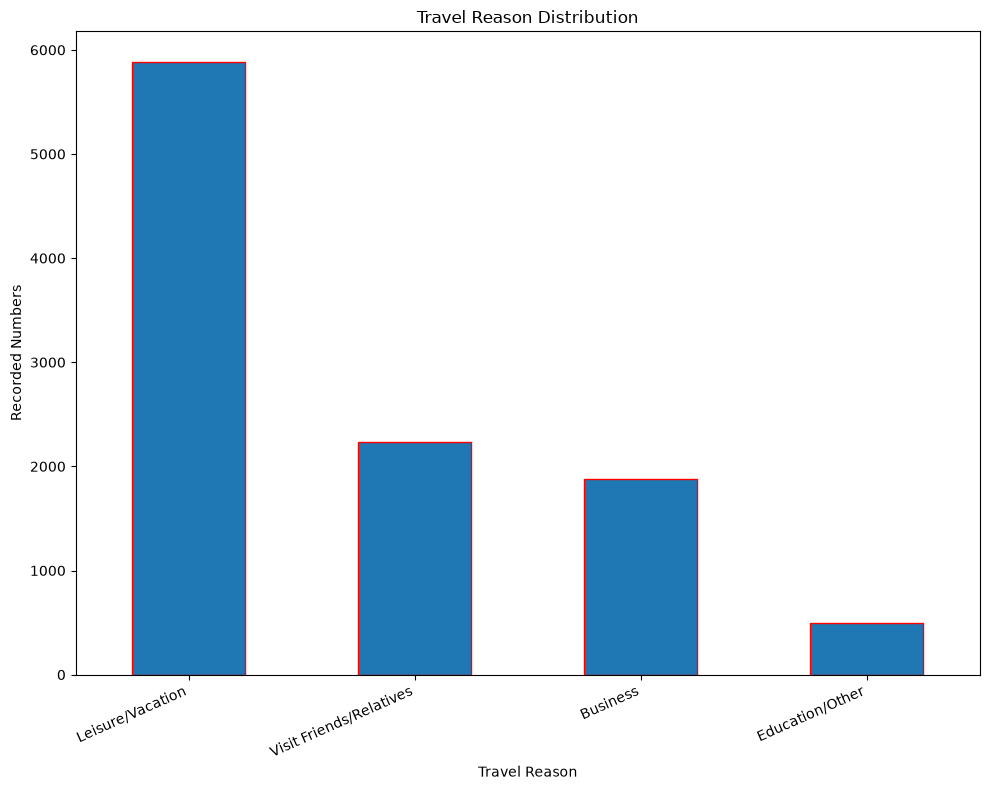

In [37]:
travellers_count=(
    df_analysis["Travel_Reason"].value_counts().sort_values(ascending=False)
)
plt.figure(figsize=(10,8))

travellers_count.plot(
    kind="bar",
    edgecolor="red"

)

plt.title("Travel Reason Distribution")
plt.xlabel("Travel Reason")
plt.ylabel("Recorded Numbers")
plt.xticks(rotation=24,ha="right")
plt.tight_layout()
plt.show()

 ### Distribution of Travel Purposes

Leisure/vacation was the largest travel-purpose category, accounting for 5,884 records (approximately 56.0% of the dataset). Visits to friends or relatives represented 2,234 records (21.3%), while business travel accounted for 1,883 records (17.9%). Education/Other was the smallest category, with 499 records (4.8%).

This distribution shows that the dataset covers several travel motivations, although leisure travel is the dominant category. The subsequent business-versus-leisure analysis therefore addresses a focused research question within the broader dataset.

In [38]:
# Check all destinations and their year coverage
print("Travel destinations:")
print(sorted(df_analysis["Destination_State"].dropna().unique()))

print("\nBEA destinations:")
print(sorted(df_bea_state_year["Destination_State"].dropna().unique()))

print("\nCoverage by destination:")
display(
    df_bea_state_year.groupby("Destination_State")
    .agg(
        Years_Available=("Year", "nunique"),
        First_Year=("Year", "min"),
        Last_Year=("Year", "max"),
        Missing_Income=("Per_Capita_Income", "sum"),
        Missing_Disposable_Income=(
            "Per_Capita_Disposable_Income",
            lambda x: x.isna().sum()
        ),
        Missing_RPP=(
            "Regional_Price_Parity",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

print(
    "\nDuplicate destination-year rows:",
    df_bea_state_year.duplicated(
        subset=["Destination_State", "Year"]
    ).sum()
)

Travel destinations:
['California', 'District of Columbia', 'Florida', 'Illinois', 'Nevada', 'New York']

BEA destinations:
['California', 'Florida', 'Illinois', 'Nevada']

Coverage by destination:


,Destination_State,Years_Available,First_Year,Last_Year,Missing_Income,Missing_Disposable_Income,Missing_RPP
0,California,28,1998,2025,1452860.0,0,11
1,Florida,28,1998,2025,1256340.0,0,11
2,Illinois,28,1998,2025,1357930.0,0,11
3,Nevada,28,1998,2025,1239193.0,0,11



Duplicate destination-year rows: 0


### latest comparison per year

In [39]:


income_columns = [
    "Per_Capita_Income",
    "Per_Capita_Disposable_Income",
    "Regional_Price_Parity"
]

print("Missing values by indicator:")
display(df_bea_state_year[income_columns].isna().sum())


quality_year = (
    df_bea_state_year.groupby("Year").agg(
        Destinations=("Destination_State", "nunique"),
        Income_Complete=(
            "Per_Capita_Income",
            lambda x: x.notna().all()
        ),
        Disposable_Income_Complete=(
            "Per_Capita_Disposable_Income",
            lambda x: x.notna().all()
        ),
        RPP_Complete=(
            "Regional_Price_Parity",
            lambda x: x.notna().all()
        )
    )
)

complete_years = quality_year[
    (quality_year["Destinations"] == 6)
    & quality_year["Income_Complete"]
    & quality_year["Disposable_Income_Complete"]
    & quality_year["RPP_Complete"]
]


if complete_years.empty:
    print("No year has complete data for all six destinations.")
else:
    latest_common_year = int(complete_years.index.max())

    print("Latest complete comparison year:", latest_common_year)

    display(
        df_bea_state_year[
            df_bea_state_year["Year"] == latest_common_year
        ].sort_values("Destination_State")
    )


Missing values by indicator:


Per_Capita_Income                0
Per_Capita_Disposable_Income     0
Regional_Price_Parity           44
dtype: int64

No year has complete data for all six destinations.


In [40]:


economic_context = (
    df_bea_state_year[
        df_bea_state_year["Year"] == latest_common_year
    ]
    .rename(columns={"Year": "BEA_Reference_Year"})
    .copy()
)

economic_context = economic_context[
    [
        "Destination_State",
        "BEA_Reference_Year",
        "Per_Capita_Income",
        "Per_Capita_Disposable_Income",
        "Regional_Price_Parity"
    ]
]

print(
    "Duplicate destinations in economic data:",
    economic_context["Destination_State"].duplicated().sum()
)


df_analysis_enriched = df_analysis.merge(
    economic_context,
    on="Destination_State",
    how="left",
    validate="many_to_one"
)


print("\nMERGE VALIDATION")
print("----------------")
print("Original travel records:", len(df_analysis))
print("Enriched travel records:", len(df_analysis_enriched))
print("Rows preserved:", len(df_analysis) == len(df_analysis_enriched))

print(
    "Records missing per-capita income:",
    df_analysis_enriched["Per_Capita_Income"].isna().sum()
)

print(
    "Records missing RPP:",
    df_analysis_enriched["Regional_Price_Parity"].isna().sum()
)


display(df_analysis_enriched.head())


NameError: name 'latest_common_year' is not defined

In [ ]:


destination_summary = (
    df_analysis_enriched.groupby("Destination_State")
    .agg(
        Number_of_Travelers=("Respondent", "count"),
        Average_Travel_Expenses=("Expenses", "mean"),
        Median_Travel_Expenses=("Expenses", "median"),
        Average_Pax=("Pax", "mean"),
        Per_Capita_Income=("Per_Capita_Income", "first"),
        Per_Capita_Disposable_Income=(
            "Per_Capita_Disposable_Income", "first"
        ),
        Regional_Price_Parity=("Regional_Price_Parity", "first")
    )
    .reset_index()
)


numeric_columns = destination_summary.select_dtypes(
    include="number"
).columns

destination_summary[numeric_columns] = (
    destination_summary[numeric_columns].round(2)
)


destination_summary = destination_summary.sort_values(
    "Average_Travel_Expenses",
    ascending=False
)

display(destination_summary)


,Destination_State,Number_of_Travelers,Average_Travel_Expenses,Median_Travel_Expenses,Average_Pax,Per_Capita_Income,Per_Capita_Disposable_Income,Regional_Price_Parity
3,Illinois,641,1586.14,1446.06,1.92,75507.0,65731.0,99.96
1,District of Columbia,636,1584.39,1442.82,1.98,115442.0,96558.0,109.90
5,New York,2635,1569.52,1417.75,1.95,86835.0,73357.0,107.92
4,Nevada,1018,1567.67,1443.18,1.91,70490.0,62831.0,99.98
2,Florida,3158,1550.11,1417.74,1.93,74880.0,66545.0,103.41
0,California,2412,1506.46,1361.84,1.90,86761.0,74152.0,110.72


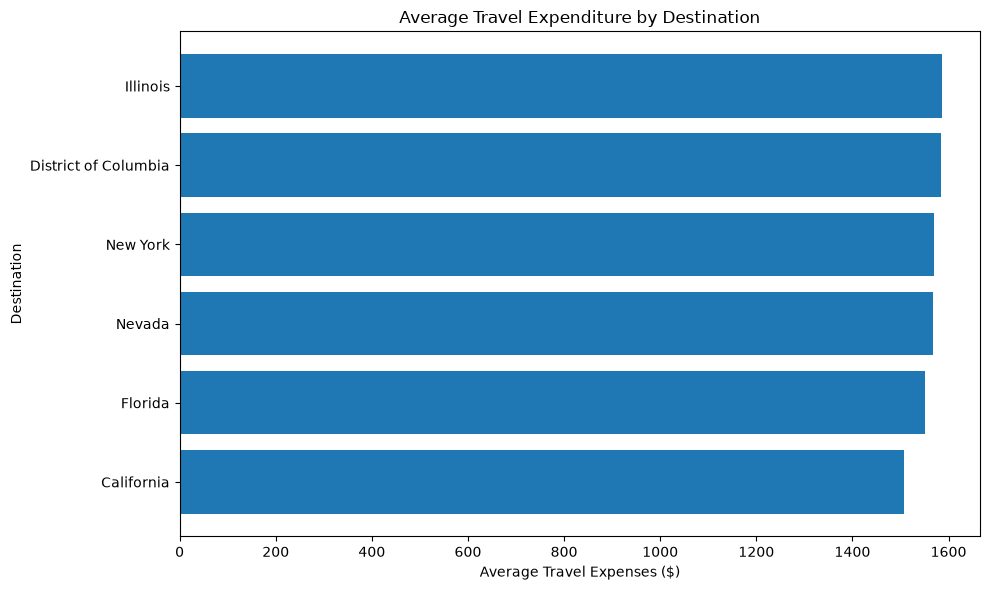

In [ ]:
plot_data = destination_summary.sort_values(
    "Average_Travel_Expenses",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Destination_State"],
    plot_data["Average_Travel_Expenses"]
)

plt.xlabel("Average Travel Expenses ($)")
plt.ylabel("Destination")
plt.title("Average Travel Expenditure by Destination")
plt.tight_layout()
plt.show()


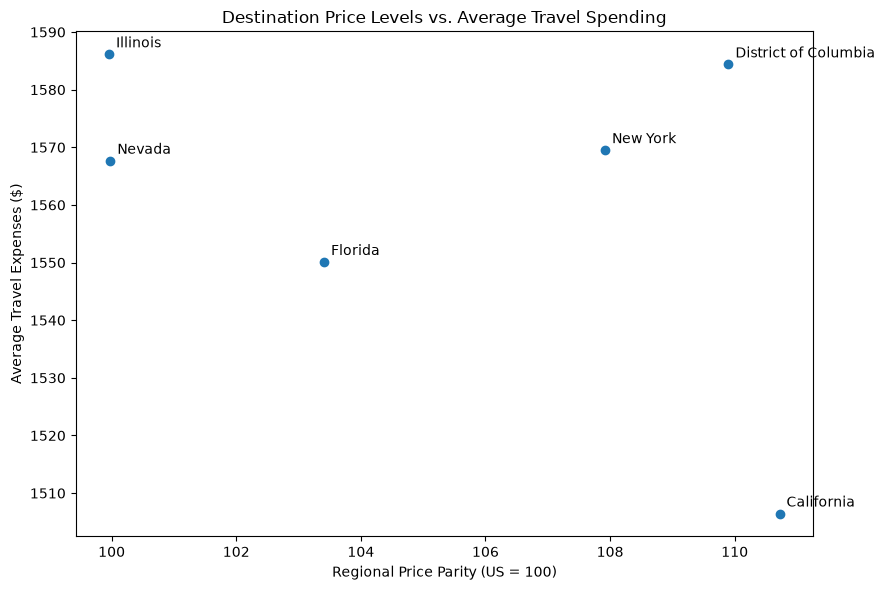

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    destination_summary["Regional_Price_Parity"],
    destination_summary["Average_Travel_Expenses"]
)

for _, row in destination_summary.iterrows():
    plt.annotate(
        row["Destination_State"],
        (
            row["Regional_Price_Parity"],
            row["Average_Travel_Expenses"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Regional Price Parity (US = 100)")
plt.ylabel("Average Travel Expenses ($)")
plt.title("Destination Price Levels vs. Average Travel Spending")
plt.tight_layout()
plt.show()


In [ ]:


correlation, p_value = spearmanr(
    destination_summary["Regional_Price_Parity"],
    destination_summary["Average_Travel_Expenses"]
)

print(f"Spearman correlation: {correlation:.3f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("The association is statistically significant at alpha = 0.05.")
else:
    print("The association is not statistically significant at alpha = 0.05.")

print(
    "Caution: this analysis uses only six destination-level observations."
)


Spearman correlation: -0.486
P-value: 0.3287
The association is not statistically significant at alpha = 0.05.
Caution: this analysis uses only six destination-level observations.


### Spearman Correlation: Regional Price Parity and Travel Expenditure

Spearman's rank correlation was used to explore the relationship between destination-level Regional Price Parity (RPP) and average recorded travel expenditure across six US destinations. The analysis produced a correlation coefficient of −0.486 and a p-value of 0.3287.

The negative coefficient suggests a moderate inverse rank association: destinations with higher price parity tended to have lower average recorded travel expenditure in this sample. However, the relationship was not statistically significant at the 5% significance level. Therefore, the null hypothesis was not rejected.

The findings should be interpreted cautiously because the analysis includes only six destination-level observations. The results do not establish causation and should be treated as exploratory rather than conclusive evidence about the relationship between local price levels and traveler spending.

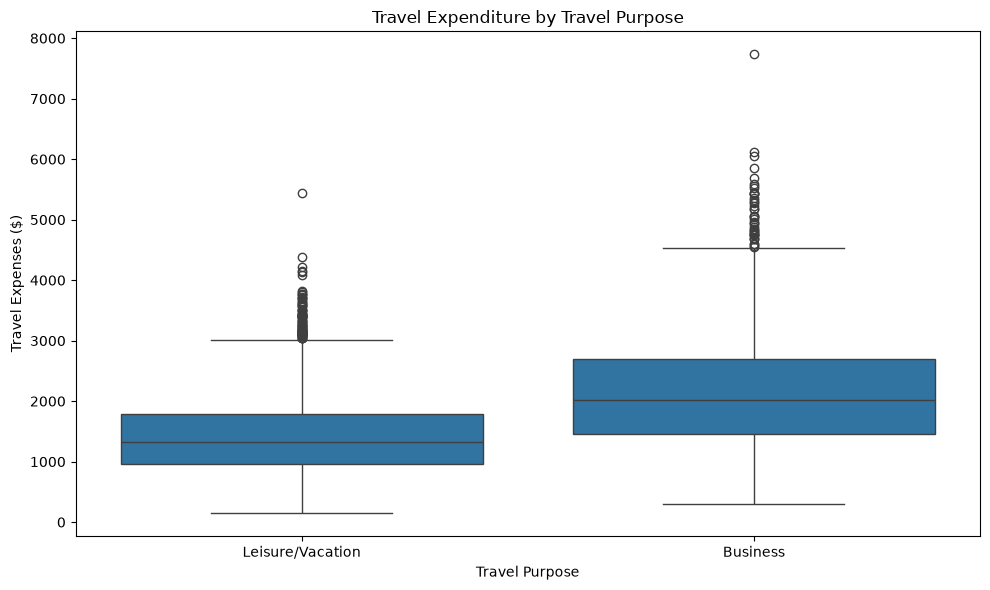

In [ ]:
df_business_leisure = df_analysis_enriched[
    df_analysis_enriched["Travel_Reason"].isin(
        ["Business", "Leisure/Vacation"]
    )
].copy()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_business_leisure,
    x="Travel_Reason",
    y="Expenses"
)

plt.title("Travel Expenditure by Travel Purpose")
plt.xlabel("Travel Purpose")
plt.ylabel("Travel Expenses ($)")
plt.tight_layout()
plt.show()


,Travel_Reason,Number_of_Travelers,Average_Expenses,Median_Expenses
0,Business,1883,2177.45,2026.22
1,Leisure/Vacation,5884,1416.16,1330.91


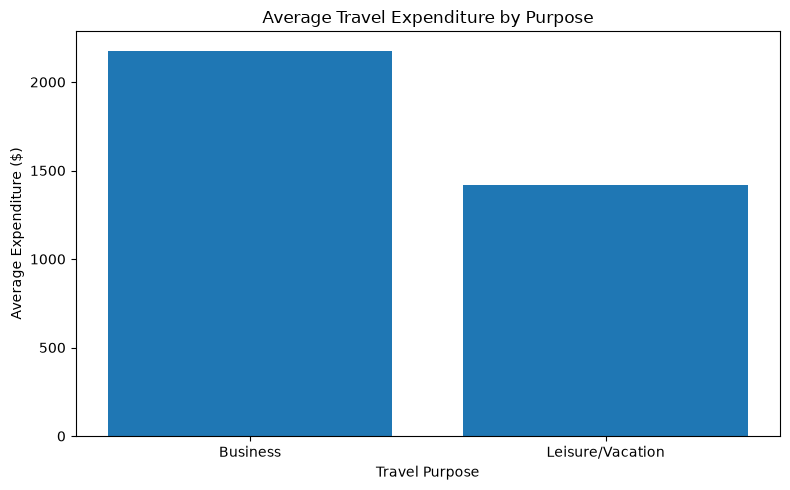

In [ ]:

purpose_summary = (
    df_business_leisure.groupby("Travel_Reason")
    .agg(
        Number_of_Travelers=("Respondent", "count"),
        Average_Expenses=("Expenses", "mean"),
        Median_Expenses=("Expenses", "median")
    )
    .reset_index()
)

display(purpose_summary.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    purpose_summary["Travel_Reason"],
    purpose_summary["Average_Expenses"]
)

plt.title("Average Travel Expenditure by Purpose")
plt.xlabel("Travel Purpose")
plt.ylabel("Average Expenditure ($)")
plt.tight_layout()
plt.show()


### Travel Expenditure by Purpose

The analysis compared travel expenditure among 1,883 business travel records and 5,884 leisure/vacation travel records. Business travelers recorded a mean expenditure of $2,177.45 and a median of $2,026.22. In comparison, leisure/vacation travelers recorded a mean of $1,416.16 and a median of $1,330.91.

The mean expenditure for business travel was $761.29 higher, representing approximately 53.8% more than leisure/vacation expenditure. The median difference of $695.31 showed a similar pattern. These descriptive results, together with the previously conducted Welch's t-test and large Cohen's d effect size, indicate a substantial difference in expenditure between the two travel-purpose groups in this dataset.

In [ ]:

from scipy.stats import mannwhitneyu

business_expenses = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Business",
    "Expenses"
].dropna()

leisure_expenses = df_business_leisure.loc[
    df_business_leisure["Travel_Reason"] == "Leisure/Vacation",
    "Expenses"
].dropna()

u_statistic, p_value_mw = mannwhitneyu(
    business_expenses,
    leisure_expenses,
    alternative="two-sided"
)

print("MANN-WHITNEY U TEST")
print("-------------------")
print(f"U statistic: {u_statistic:.2f}")
print(f"P-value: {p_value_mw:.6g}")

if p_value_mw < 0.05:
    print("Result: The distributions differ statistically significantly.")
else:
    print("Result: No statistically significant distribution difference detected.")


MANN-WHITNEY U TEST
-------------------
U statistic: 8283842.00
P-value: 2.59988e-230
Result: The distributions differ statistically significantly.


### Mann–Whitney U Test: Travel Expenditure by Purpose

A two-sided Mann–Whitney U test was conducted to compare travel-expenditure distributions for business travelers (n = 1,883) and leisure/vacation travelers (n = 5,884). The test returned a U statistic of 8,283,842 and a p-value of approximately 2.60 × 10⁻²³⁰.

At the 5% significance level, the null hypothesis was rejected. The result provides strong statistical evidence that travel-expenditure distributions differ between the two groups. Descriptive statistics showed that business travelers had higher mean and median expenditure than leisure/vacation travelers. This conclusion is consistent with the previously conducted Welch's t-test and the large Cohen's d effect size.

The results demonstrate an association between travel purpose and expenditure in this dataset; they do not establish that travel purpose alone causes the difference.

In [ ]:


n_business = len(business_expenses)
n_leisure = len(leisure_expenses)

u_statistic, p_value_mw = mannwhitneyu(
    business_expenses,
    leisure_expenses,
    alternative="two-sided"
)

common_language_effect = u_statistic / (
    n_business * n_leisure
)

rank_biserial = 2 * common_language_effect - 1

print(f"Business observations: {n_business}")
print(f"Leisure observations: {n_leisure}")
print(
    "Probability of business expense exceeding leisure expense "
    "(ties receive half credit): "
    f"{common_language_effect:.3f}"
)
print(f"Rank-biserial correlation: {rank_biserial:.3f}")


Business observations: 1883
Leisure observations: 5884
Probability of business expense exceeding leisure expense (ties receive half credit): 0.748
Rank-biserial correlation: 0.495


### Effect Size: Business versus Leisure Expenditure

The Mann–Whitney U analysis produced a probability-of-superiority estimate of 0.748 and a rank-biserial correlation of 0.495. This indicates that a randomly selected business-travel expenditure is higher than a randomly selected leisure/vacation expenditure approximately 74.8% of the time, counting ties as half a comparison.

The positive rank-biserial correlation indicates that business expenditures tend to rank higher than leisure expenditures. Combined with the statistically significant Mann–Whitney test, Welch's t-test, and Cohen's d of approximately 1.056, these findings indicate a meaningful difference in expenditure patterns between the two travel-purpose groups in this dataset.

In [ ]:


project_dir = Path.home() / "Desktop" / "pydata_capstoneproject"

project_dir.mkdir(parents=True, exist_ok=True)


output_path = project_dir / "travel_analysis_enriched.csv"
df_analysis_enriched.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path.resolve())
print("Number of rows:", len(df_analysis_enriched))
print("Number of columns:", len(df_analysis_enriched.columns))


Dataset saved successfully!
File location: C:\Users\PatrickNjuguna\Desktop\pydata_capstoneproject\travel_analysis_enriched.csv
Number of rows: 10500
Number of columns: 12
